# CSDA STAC search: planet data at Sites

Summary:  
+ read in a sites geojson
+ compile a STAC search at site for a time period for vendor imagery
+ plot the footprints of the results
+ next step (todo) - how to access the image data for analysis?

#### Resources:
+ https://nasa-impact.github.io/csda-client/latest/examples/search-and-download/#finding-planet-data

| Author | Affiliation | Date |
| ---------------- | ---------------- | ---------------- |
| Paul Montesano, PhD | NASA Goddard Space Flight Center; ESSIC | July 2026 |

In [ ]:
#pip install contextily
#pip install matplotlib_scalebar

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from urllib.parse import quote
import numpy as np

import sys

# sys.path.append('/projects/code/csda_summaries/lib')
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import csdalib
import staclib
import siteslib

from datetime import datetime
from multiprocessing import Pool, cpu_count
from functools import partial
from tqdm import tqdm
import importlib

In [2]:
from pathlib import Path
STAC_CACHE_PATH = Path("/explore/nobackup/people/pmontesa/stac_cache")
STAC_CACHE_PATH.mkdir(parents=True, exist_ok=True)

## CSDA Evaluation Sites

Our database of `CSDA Evaluation Sites` is a critical & foundational set of information for CSDA SME work. Each site, uniquely identified with a `Site Name` and a specific geographic extent (AOI), provides some sort of radiometric or geometric reference for evaluation commercial imagery.

#### Read in our CSDA sites GeoJSON (AOIs) directly from GitHub

In [68]:
SITES_STR = 'csda' #'eval' #'csda'
SITES_FN = f'{SITES_STR}_sites_aoi.geojson'

In [69]:
# SITES_STR = 'hls_processed_tiles'
# SITES_FN = f'{SITES_STR}.geojson'

In [70]:
RAW_BASE = 'https://raw.githubusercontent.com/pahbs/csda_summaries/master'

sites_url = f'{RAW_BASE}/sites/{SITES_FN}'

sites_gdf = gpd.read_file(sites_url)
print(f"{sites_gdf.shape[0]} site AOIs, which are extents of various sizes and shapes, ranging from tiny corner reflector locations, to boxes and circles, to larger custom polygons.")

237 site AOIs, which are extents of various sizes and shapes, ranging from tiny corner reflector locations, to boxes and circles, to larger custom polygons.


In [74]:
BUF_KM = 0

In [2]:
DO_SITE_SUBSET = False
RADCALNET = False
DO_GLOBAL = True

In [106]:
if DO_SITE_SUBSET:
    if RADCALNET:
        SITES_STR = 'RadCalNet'
        sites_gdf = sites_gdf[sites_gdf.Source == SITES_STR]
    else:
        #SITENAME = 'Bonanza_Creek'
        # SITENAME = 'PICS Libya-4'
        SITENAME = 'Railroad Valley'
        SITES_STR = SITENAME.replace(' ','.')
        sites_gdf = sites_gdf[sites_gdf['Site Name'] == SITENAME]


# Table of CSDA STAC Collections

Here is what data we can find in the CSDA STAC

In [109]:
import pystac_client

# Define target CSDA STAC endpoint
STAC_URL = "https://csdap.earthdata.nasa.gov/stac"

try:
    # 1. Test API connection and structural validation
    print(f"Connecting to {STAC_URL}...")
    catalog = pystac_client.Client.open(STAC_URL)
    print(f"SUCCESS: Connected to API ID: {catalog.id}")
    #print(f"STAC Version supported: {catalog.stac_version}\n")
    
    # 2. Test the query engine by pulling a single item limit
    print("Testing search capabilities...")
    search = catalog.search(max_items=1)
    items = list(search.items())
    
    print(f"SUCCESS: Search engine returned {len(items)} record(s) correctly.")
    
except Exception as e:
    print(f"API ERROR: Connection or query parsing failed.\nDetails: {e}")


Connecting to https://csdap.earthdata.nasa.gov/stac...
SUCCESS: Connected to API ID: stac-fastapi
Testing search capabilities...
SUCCESS: Search engine returned 1 record(s) correctly.


In [110]:
import requests
from IPython.display import Markdown, display

STAC_API_URL = 'https://csdap.earthdata.nasa.gov/stac'

# Get collections
response = requests.get(f'{STAC_API_URL}/collections')
data = response.json()

collections = data.get('collections', [])

# Build markdown
markdown_output = f"# CSDA STAC Collections\n\n"
markdown_output += f"**Total Collections:** {len(collections)}\n\n"
markdown_output += "| ID | Title | Description | Temporal Coverage |\n"
markdown_output += "|:---|:---|:---|:---|\n"

for collection in collections:
    col_id = collection.get('id', 'N/A')
    title = collection.get('title', 'N/A')
    description = collection.get('description', 'N/A')
    
    # Truncate and clean description
    if description and description != 'N/A':
        description = description.replace('\n', ' ').replace('\r', '')
        if len(description) > 100:
            description = description[:100] + '...'
        description = description.replace('|', '\\|')
    
    # Get temporal extent with safe None checks
    temporal_str = 'N/A'
    try:
        extent = collection.get('extent')
        if extent and isinstance(extent, dict):
            temporal = extent.get('temporal')
            if temporal and isinstance(temporal, dict):
                intervals = temporal.get('interval', [])
                if intervals and isinstance(intervals, list) and len(intervals) > 0:
                    if intervals[0] and isinstance(intervals[0], list) and len(intervals[0]) > 0:
                        start = intervals[0][0] if intervals[0][0] else 'Unknown'
                        end = intervals[0][1] if len(intervals[0]) > 1 and intervals[0][1] else 'Present'
                        
                        # Format dates nicely
                        if isinstance(start, str) and start not in ['Unknown', 'N/A']:
                            start = start.split('T')[0]
                        if isinstance(end, str) and end not in ['Present', 'N/A']:
                            end = end.split('T')[0]
                        
                        temporal_str = f"{start} to {end}"
    except Exception as e:
        # If anything goes wrong, just leave as N/A
        pass
    
    # Create collection link
    collection_url = f"{STAC_API_URL}/collections/{col_id}"
    col_id_link = f"[{col_id}]({collection_url})"
    
    markdown_output += f"| {col_id_link} | {title} | {description} | {temporal_str} |\n"

# Display in notebook
display(Markdown(markdown_output))

# Save to file
with open(f'{STAC_CACHE_PATH}/stac_collections.md', 'w') as f:
    f.write(markdown_output)

print("\n✓ Saved to stac_collections.md")

# CSDA STAC Collections

**Total Collections:** 22

| ID | Title | Description | Temporal Coverage |
|:---|:---|:---|:---|
| [umbra](https://csdap.earthdata.nasa.gov/stac/collections/umbra) | Umbra | Umbra Space | 2023-11-02 to 2026-09-23 |
| [desis](https://csdap.earthdata.nasa.gov/stac/collections/desis) | DESIS | Teledyne Brown Engineering, Inc – DESIS | 2018-08-30 to 2024-05-25 |
| [pixxel](https://csdap.earthdata.nasa.gov/stac/collections/pixxel) | Pixxel | Pixxel | 2025-06-21 to 2026-06-13 |
| [planetiq](https://csdap.earthdata.nasa.gov/stac/collections/planetiq) | PlanetiQ | PlanetiQ | 2024-01-18 to 2025-03-24 |
| [satellogic](https://csdap.earthdata.nasa.gov/stac/collections/satellogic) | Satellogic | Satellogic Inc. | 2021-02-02 to 2026-09-22 |
| [geooptics](https://csdap.earthdata.nasa.gov/stac/collections/geooptics) | GeoOptics | geooptics | 2020-01-01 to 2021-04-30 |
| [spire](https://csdap.earthdata.nasa.gov/stac/collections/spire) | Spire | Spire | 2019-11-01 to 2025-08-09 |
| [airbus-dem](https://csdap.earthdata.nasa.gov/stac/collections/airbus-dem) | Airbus - DEM | Airbus - DEM | 2025-09-19 to 2026-04-13 |
| [iceye](https://csdap.earthdata.nasa.gov/stac/collections/iceye) | Iceye | ICEYE US | 2019-10-17 to 2026-09-23 |
| [tomorrow](https://csdap.earthdata.nasa.gov/stac/collections/tomorrow) | Tomorrow | The Tomorrow Companies Inc. | 2023-06-24 to 2026-02-22 |
| [pgc-earthdem](https://csdap.earthdata.nasa.gov/stac/collections/pgc-earthdem) | EarthDEM | EarthDEM | 2002-02-06 to 2024-07-01 |
| [maxar-sdx](https://csdap.earthdata.nasa.gov/stac/collections/maxar-sdx) | Maxar DEM | Maxar Technologies – Precision 3D | 2008-01-18 to 2025-05-26 |
| [capellaspace](https://csdap.earthdata.nasa.gov/stac/collections/capellaspace) | CapellaSpace | capellaspace | 2020-12-26 to 2026-09-22 |
| [airbus](https://csdap.earthdata.nasa.gov/stac/collections/airbus) | Airbus U.S.- SAR | Airbus U.S. | 2007-11-19 to 2026-08-20 |
| [maxar-legion](https://csdap.earthdata.nasa.gov/stac/collections/maxar-legion) | Maxar Legion | Maxar Technologies Inc. | 2024-09-11 to 2026-09-21 |
| [airbus-optical](https://csdap.earthdata.nasa.gov/stac/collections/airbus-optical) | Airbus U.S.- Optical | Airbus U.S.- Optical | 2021-08-15 to 2026-08-30 |
| [ghgsat](https://csdap.earthdata.nasa.gov/stac/collections/ghgsat) | GHGSat | GHGSat | 2021-01-03 to 2026-08-13 |
| [blacksky](https://csdap.earthdata.nasa.gov/stac/collections/blacksky) | BlackSky | BlackSky Technology, Inc. | 2019-05-07 to 2026-08-17 |
| [kuvaspace](https://csdap.earthdata.nasa.gov/stac/collections/kuvaspace) | kuvaspace | Kuva Space | Unknown to Present |
| [planet](https://csdap.earthdata.nasa.gov/stac/collections/planet) | Planet | Planet | 2009-03-09 to 2026-07-18 |
| [mda](https://csdap.earthdata.nasa.gov/stac/collections/mda) | MDA | MDA Space | Unknown to Present |
| [hydrosat](https://csdap.earthdata.nasa.gov/stac/collections/hydrosat) | hydrosat | HydroSat | 2025-09-29 to 2025-09-29 |



✓ Saved to stac_collections.md


### Create site dicts for all sites

In [111]:
def create_global_grid(grid_size=30):
    """
    Create a grid of sub-regions covering the globe.
    
    Parameters:
    -----------
    grid_size : int
        Size of each grid cell in degrees (default 30° = 12x6 grid)
    
    Returns:
    --------
    dict : Dictionary of site_dicts for each grid cell
    """
    site_dicts = {}
    
    # Create grid from -180 to 180 longitude, -90 to 90 latitude
    lons = range(-180, 180, grid_size)
    lats = range(-90, 90, grid_size)
    
    for i, lon_start in enumerate(lons):
        for j, lat_start in enumerate(lats):
            lon_end = min(lon_start + grid_size, 180)
            lat_end = min(lat_start + grid_size, 90)
            
            # Create unique name for this grid cell
            grid_name = f"grid_{i:02d}_{j:02d}"
            
            # Calculate center point
            center_lon = (lon_start + lon_end) / 2
            center_lat = (lat_start + lat_end) / 2
            
            site_dicts[grid_name] = {
                'bbox': [lon_start, lat_start, lon_end, lat_end],
                'lon': center_lon,
                'lat': center_lat,
                'buffer': None,
                'geom_type': 'Polygon'
            }
    
    return site_dicts

In [112]:
# Usage in your code:
if DO_GLOBAL:
    # Global search - break into grid
    SITENAME = 'Global'
    SITES_STR = SITENAME.replace(' ', '.')
    
    # Create grid (adjust grid_size as needed: 30°, 20°, 10°, etc.)
    site_dicts = create_global_grid(grid_size=10)  # 30° = 12x6 = 72 regions
    
    print(f"Global search broken into {len(site_dicts)} sub-regions")
else:
    site_dicts = staclib.create_site_dict_from_gdf(sites_gdf, site_name_field='Site Name', buffer_degrees=0)

# Convert to list of tuples for processing
CSDA_EVAL_SITE_ITEMS = list(site_dicts.items())

In [113]:
len(site_dicts)

1

# Multiprocess search across all CSDA Evaluation Sites for a vendor

### Configure search

In [114]:
TODAY = datetime.now().strftime('%Y-%m-%d')
START_OF_COMMERCIAL_ERA = '1999-01-01'

In [115]:
# Alaska search
COLLECTION_LIST = ['planet','airbus-optical','satellogic','maxar-legion']
YEAR = 2019 #2024
START_DATE = f'{YEAR}-01-01'
#START_DATE = START_OF_COMMERCIAL_ERA
END_DATE = f'{YEAR+1}-01-01'
#END_DATE = '2019-12-31'
MONTH_LIST = [6,7,8]

In [116]:
# Misc search
COLLECTION_LIST = ['planet']
YEAR = 'allyears'
START_DATE = START_OF_COMMERCIAL_ERA
# YEAR = 2024
# START_DATE = f'{YEAR}-01-01'
END_DATE = TODAY
#END_DATE = '2019-12-31'
MONTH_LIST = list(range(1,12+1))

In [117]:
CSDA_EVAL_SITE_ITEMS = list(site_dicts.items())

### Multiprocess SDX search across CSDA Eval sites

In [118]:
import importlib
importlib.reload(staclib)

<module 'staclib' from '/home/pmontesa/code/csda_summaries/lib/staclib.py'>

In [120]:
search_func = partial(staclib.stac_search_site, end_date=END_DATE, start_date=START_DATE,  months=MONTH_LIST,
                      collections=COLLECTION_LIST
                     )
#search_func = partial(search_site, today=today, start_date='2010-01-01', collections=['maxar'])

n_processes = max(1, cpu_count() - 4)
print(f"Using {n_processes} processes to search {len(CSDA_EVAL_SITE_ITEMS)} sites\n")

# Run with progress bar
with Pool(processes=n_processes) as pool:
    results = list(tqdm(
        pool.imap(search_func, CSDA_EVAL_SITE_ITEMS),
        total=len(CSDA_EVAL_SITE_ITEMS),
        desc="Searching sites"
    ))

# Collect and report results
stac_gdf_list = []
stac_items_list = []
print("\nResults by site:")
for site_name, gdf, items, message in results:
    print(f"  {site_name}: {message}")
    if gdf is not None:
        stac_gdf_list.append(gdf)
        stac_items_list.extend(items)

# Combine
if stac_gdf_list:
    stac_gdf = pd.concat(stac_gdf_list, ignore_index=True)
    print(f"\n{'='*60}")
    print(f"Total: {len(stac_gdf)} items from {stac_gdf['site_name'].nunique()} sites")
    print(f"{'='*60}")
    print("\nItems per site:")
    print(stac_gdf['site_name'].value_counts())
else:
    print("\nNo items found")
    stac_gdf = gpd.GeoDataFrame()

Using 36 processes to search 1 sites



Searching sites: 100%|██████████| 1/1 [00:13<00:00, 13.65s/it]


Results by site:
  Railroad Valley: Found 1069 items across 28 interval(s) (months=[6, 7, 8])

Total: 1069 items from 1 sites

Items per site:
Railroad Valley    1069
Name: site_name, dtype: int64


In [121]:
#ic[100].assets
stac_gdf.shape

(1069, 119)

## Save items & footprints: 

SDX STAC search results to JSON & geopackage

In [122]:
stac_gdf = stac_gdf.drop(columns=[col for col in stac_gdf.columns if 'asset' in col])

# Convert list columns to strings
stac_gdf_copy = stac_gdf.copy()
for col in stac_gdf_copy.columns:
    if stac_gdf_copy[col].apply(lambda x: isinstance(x, list)).any():
        stac_gdf_copy[col] = stac_gdf_copy[col].apply(lambda x: str(x) if isinstance(x, list) else x)
        
stac_gdf_copy.to_parquet(str(STAC_CACHE_PATH / f"stac_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.parquet"))

In [123]:
from pystac import ItemCollection

ic = ItemCollection(stac_items_list)
ic.save_object(str(STAC_CACHE_PATH / f"stac_items_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.json"))

## Plot STAC results info

In [124]:
# # ── Read back (full) ──────────────────────────────────────────────────────────
# stac_gdf = gpd.read_parquet(str(STAC_CACHE_PATH / f"stac_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.parquet"))

In [125]:
#stac_gdf[['pl:provider', 'pl:item_type','pl:satellite_id', 'pl:product_id','collection', 'eo:instrument']]

In [126]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from shapely.geometry import Polygon

from matplotlib.colors import LogNorm

In [127]:
# # 1. Define target projection string
# eckert_vi_crs  = '+proj=eck6  +lon_0=0 +x_0=0 +y_0=0 +ellps=WGS84 +datum=WGS84 +units=m +no_defs'
# robinson_crs   = '+proj=robin +lon_0=0 +x_0=0 +y_0=0 +ellps=WGS84 +datum=WGS84 +units=m +no_defs'
# crs_selection = robinson_crs

# # 2. Build local offline global boundary canvas 
# try:
#     world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# except (AttributeError, FileNotFoundError):
#     world_box = Polygon([(-180, -90), (-180, 90), (180, 90), (180, -90)])
#     world = gpd.GeoDataFrame(index=[0], crs='EPSG:4326', geometry=[world_box])

# world_projected = world.to_crs(crs_selection)
# xmin, ymin, xmax, ymax = world_projected.total_bounds

#### Filter

In [128]:
%%time
# 3. Process STAC centroids safely - with filter tracking
filters_applied = []

# Start with full dataset
stac_gdf_heatmap = stac_gdf.copy()
initial_count = len(stac_gdf_heatmap)

# Apply filters and track them
# Filter 1: Remove duplicates
DEDUP_COL = 'id'
stac_gdf_heatmap = stac_gdf_heatmap.drop_duplicates(subset=[DEDUP_COL])

if len(stac_gdf_heatmap) < initial_count:
    filters_applied.append(f"Duplicates removed using col '{DEDUP_COL}': {initial_count - len(stac_gdf_heatmap)}")
    initial_count = len(stac_gdf_heatmap)

CPU times: user 5.56 ms, sys: 1.1 ms, total: 6.67 ms
Wall time: 5.99 ms


In [129]:
stac_gdf_heatmap.head()

,id,collection,datetime,geometry,bbox,eo:gsd,eo:epsg,pl:rows,eo:bands,pl:columns,...,pl:heavy_haze_percent,pl:light_haze_percent,pl:clear_confidence_percent,pl:visible_confidence_percent,eo:azimuth,site_name,pl:usable_data,pl:grid_cell,pl:black_fill,pl:ps4b_geometry
0,PSScene4Band-20180831_180030_1042,planet,2018-08-31T18:00:30.056894Z,"POLYGON ((-115.89356 38.53119, -115.61085 38.4...","[-115.91381222517306, 38.411384018991576, -115...",3.8,32611.0,4330.0,[],8800.0,...,0.0,0.0,99.0,99.0,NaN,Railroad Valley,NaN,NaN,NaN,NaN
1,PSScene-20180805_175817_103e,planet,2018-08-05T17:58:17.813955Z,"POLYGON ((-115.65587 38.53072, -115.67631 38.4...","[-115.6763096584224, 38.408581834720565, -115....",3.9,NaN,NaN,[],NaN,...,0.0,1.0,98.0,93.0,147.5,Railroad Valley,NaN,NaN,NaN,NaN
2,PSScene-20180805_175816_103e,planet,2018-08-05T17:58:16.758038Z,"POLYGON ((-115.63764 38.59684, -115.65812 38.5...","[-115.65811683875111, 38.47466692064009, -115....",3.9,NaN,NaN,[],NaN,...,0.0,1.0,98.0,93.0,147.5,Railroad Valley,NaN,NaN,NaN,NaN
3,PSScene-20180805_175042_1054,planet,2018-08-05T17:50:42.811878Z,"POLYGON ((-115.70865 38.57912, -115.69048 38.5...","[-115.70864557852279, 38.51027673232641, -115....",3.7,NaN,NaN,[],NaN,...,0.0,3.0,97.0,91.0,185.8,Railroad Valley,NaN,NaN,NaN,NaN
4,PSScene-20180805_175041_1054,planet,2018-08-05T17:50:41.826217Z,"POLYGON ((-115.69205 38.51700, -115.67391 38.4...","[-115.69205397211834, 38.44815357218583, -115....",3.7,NaN,NaN,[],NaN,...,0.0,4.0,97.0,92.0,177.2,Railroad Valley,NaN,NaN,NaN,NaN


In [130]:
# Filter 2: Exclude specific values across multiple columns
EXCLUDE_STR_LIST = ['PAN', 'PSH','Ortho']
EXCLUDE_COL_LIST = ['csda:item_type', 'platform','pl:item_type']

# All possible fields across CSDA STAC that indicate platform
platform_fields = ['platform',
                   'pl:provider',
                   'eo:instrument',
                   'pl:satellite_id',
                   'eo:platform',
                   'satellite_id', 'instrument',
                   'collection']

# Ensure platform column exists
if 'platform' not in stac_gdf_heatmap.columns:
    stac_gdf_heatmap['platform'] = None

# Fill platform from available fields in priority order
for field in platform_fields:
    if field in stac_gdf_heatmap.columns:
        stac_gdf_heatmap['platform'] = stac_gdf_heatmap['platform'].fillna(stac_gdf_heatmap[field])

# Check which column is available to fill the planetscope details
if 'eo:instrument' in stac_gdf_heatmap.columns:
    instrument_col = stac_gdf_heatmap['eo:instrument']
elif 'sensor' in stac_gdf_heatmap.columns:
    instrument_col = stac_gdf_heatmap['platform']
else:
    instrument_col = 'planetscope'  # Keep original value if nothing else is found

stac_gdf_heatmap['platform'] = stac_gdf_heatmap['platform'].mask(
    stac_gdf_heatmap['platform'] == 'planetscope',
    instrument_col
).fillna('Unknown')

#stac_gdf_heatmap['platform'] = stac_gdf_heatmap['platform'].fillna('Unknown')

print(f"Platform field created/updated. Unique values: {stac_gdf_heatmap['platform'].unique()}")

# Build combined exclusion mask
exclude_mask = pd.Series([False] * len(stac_gdf_heatmap), index=stac_gdf_heatmap.index)  # Match index

for col in EXCLUDE_COL_LIST:
    if col in stac_gdf_heatmap.columns:
        exclude_mask |= stac_gdf_heatmap[col].isin(EXCLUDE_STR_LIST)

# Count total exclusions
exclude_count = exclude_mask.sum()
if exclude_count > 0:
    exclude_str = ', '.join(EXCLUDE_STR_LIST)
    col_str = ', '.join(EXCLUDE_COL_LIST)
    filters_applied.append(f"{exclude_str} excluded from {col_str}: {exclude_count}")

# Apply filter
stac_gdf_heatmap = stac_gdf_heatmap[~exclude_mask]

# Add more filters as needed in the future:
# stac_gdf_heatmap = stac_gdf_heatmap[stac_gdf_heatmap['eo:cloud_cover'] < 20]
# filters_applied.append("Cloud cover < 20%")

# Create filter text for annotation
if filters_applied:
    filter_text = "Filters applied:\n" + "\n".join([f"• {f}" for f in filters_applied])
else:
    filter_text = "No filters applied"


Platform field created/updated. Unique values: ['PS2' 'PS2.SD' 'PSB.SD']


In [131]:
import importlib

In [132]:
importlib.reload(staclib)

<module 'staclib' from '/home/pmontesa/code/csda_summaries/lib/staclib.py'>

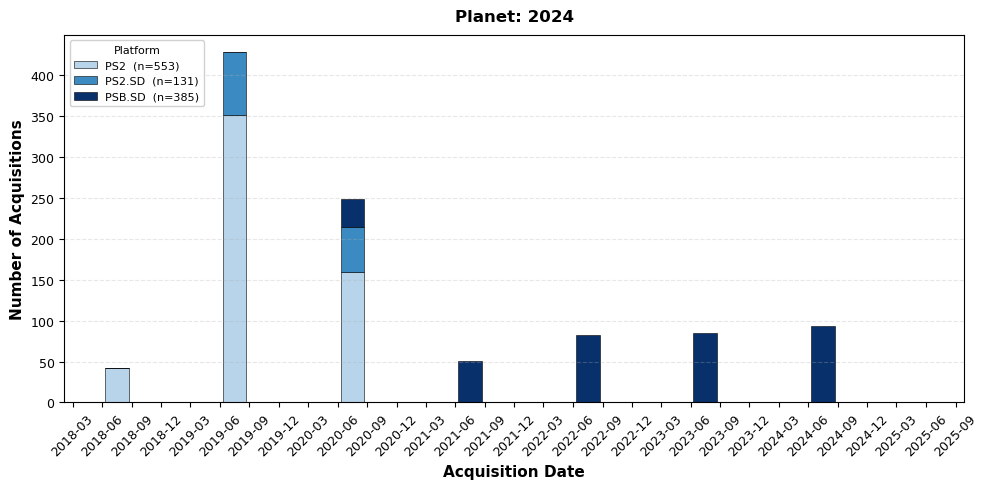

In [133]:
fig, ax = staclib.plot_acquisition_timeline(
    stac_gdf        = stac_gdf_heatmap,
    title           = 'Planet: 2024',
    interval_months = 3
)

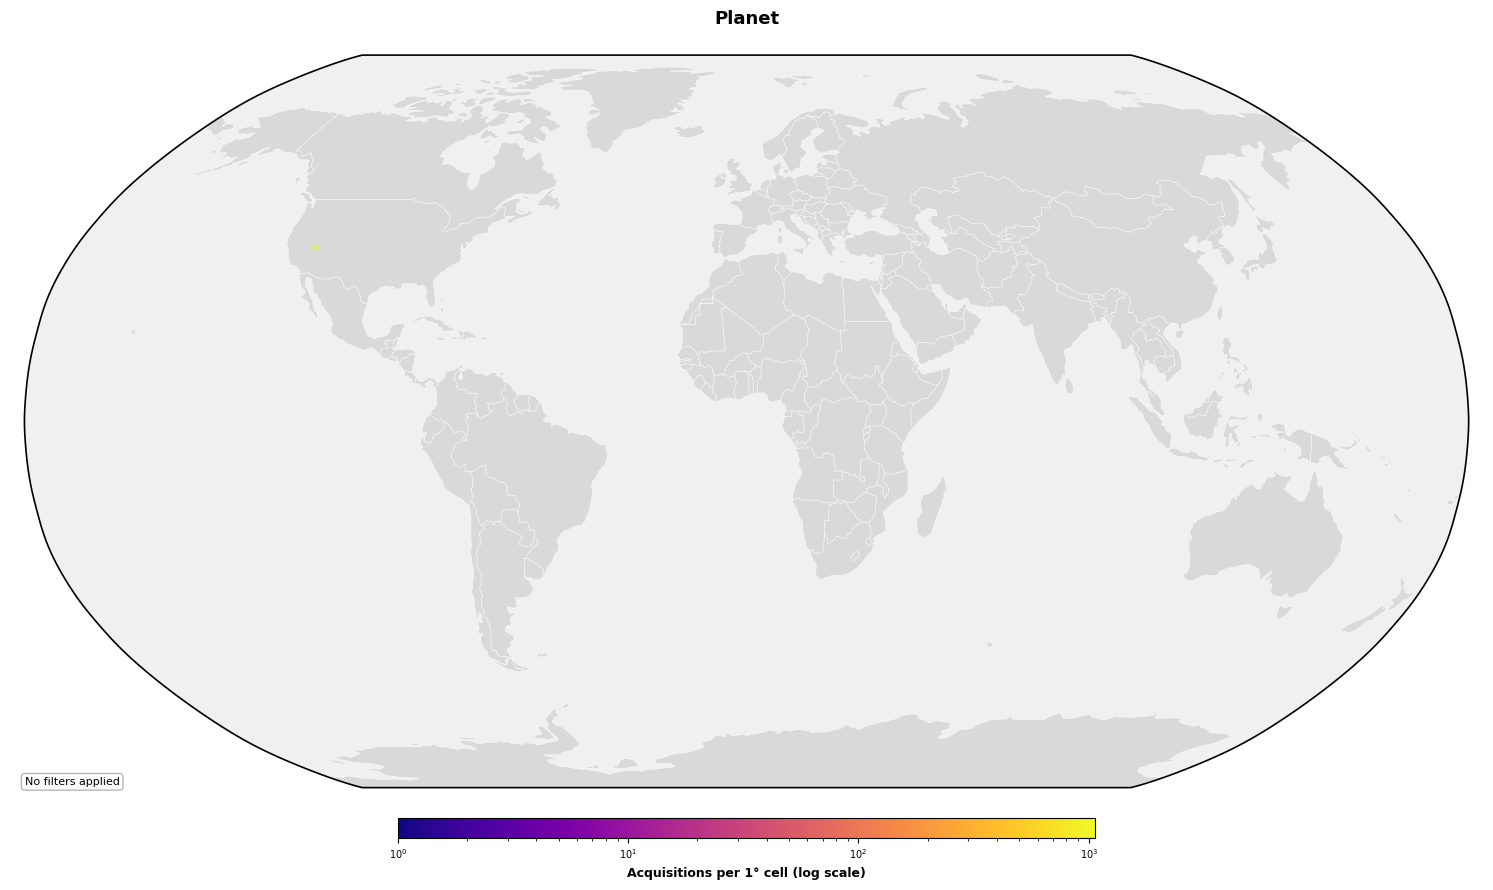

In [134]:
fig, ax = staclib.plot_stac_acquisition_density(
    stac_gdf       = stac_gdf_heatmap,
    sites_gdf      = None,
    #projection_crs = robinson_crs,
    bin_method     = 'grid',
    #gridsize       = 100,
    title          = 'Planet',
    filter_text    =  filter_text,
    figsize          = (18, 9)
)

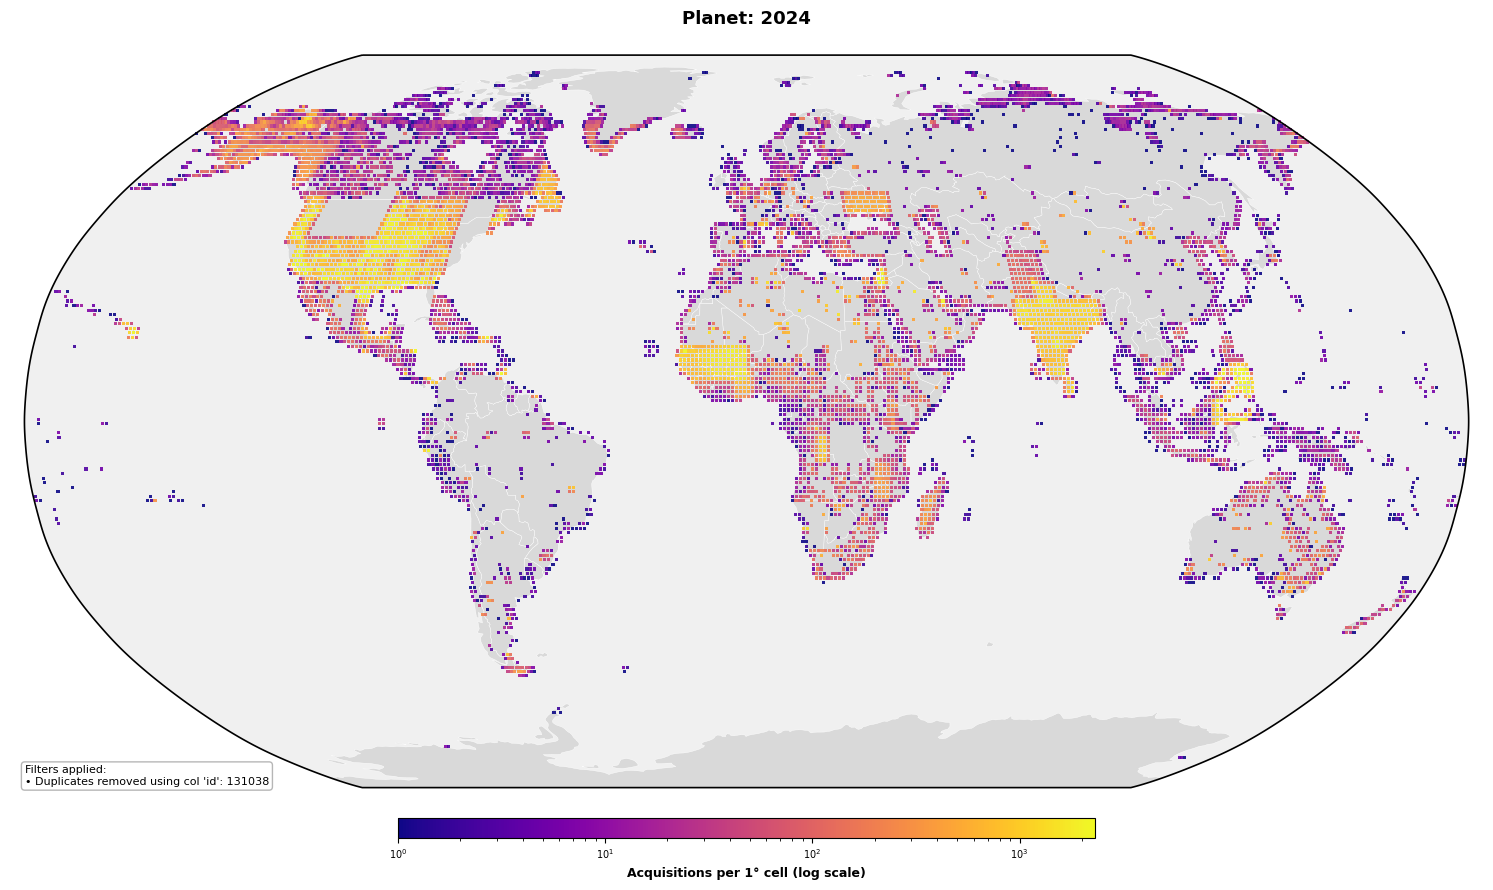

In [27]:
fig, ax = staclib.plot_stac_acquisition_density(
    stac_gdf       = stac_gdf_heatmap,
    sites_gdf      = None,
    #projection_crs = robinson_crs,
    bin_method     = 'grid',
    #gridsize       = 100,
    title          = 'Planet: 2024',
    filter_text    =  filter_text,
    figsize          = (18, 9)
)